<a href="https://colab.research.google.com/github/IvanovaKaryna/123/blob/main/%D0%9B%D0%A011_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Розпізнавання дорожніх знаків за допомогою згорткової нейронної мережі

**Датасет:** GTSRB (German Traffic Sign Recognition Benchmark), фотографії німецьких дорожніх знаків, 43 класи.

**Ціль:** навчити нейронну мережу визначати, який дорожній знак зображений на картинці.

**ПІБ студента:** Іванова Карина

**Група:** ФІТ 3-10

**Дата:** 18.11.2026

**План роботи:**
1. Завантаження набору даних
2. Перегляд зображень
3. Підготовка даних
4. Архітектура моделі
5. Навчання та криві навчання
6. Порівняння архітектур
7. Візуалізація класифікації
8. Висновки

## 1. Завантаження набору даних

In [ ]:
#Встановлюю бібліотеку для завантаження даних з Kaggle
!pip install kagglehub -q

In [ ]:
#Імпортую потрібні бібліотеки
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
#Завантажую набір даних з Kaggle
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Дані завантажено в папку:", path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Дані завантажено в папку: /kaggle/input/gtsrb-german-traffic-sign


In [ ]:
#Шукаю папку, де лежить файл Train.csv
data_dir = None
for root, dirs, files in os.walk(path):
    if "Train.csv" in files:
        data_dir = root

print("Робоча папка:", data_dir)
print(os.listdir(data_dir))

Робоча папка: /kaggle/input/gtsrb-german-traffic-sign
['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


In [ ]:
#Читаю таблиці з шляхами до картинок та правильними класами
train_df = pd.read_csv(os.path.join(data_dir, "Train.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "Test.csv"))

print("Навчальних картинок:", len(train_df))
print("Тестових картинок:", len(test_df))
train_df.head()

Навчальних картинок: 39209
Тестових картинок: 12630


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [ ]:
#Назви класів дорожніх знаків
class_names = [
    "Обмеження швидкості 20", "Обмеження швидкості 30", "Обмеження швидкості 50",
    "Обмеження швидкості 60", "Обмеження швидкості 70", "Обмеження швидкості 80",
    "Кінець обмеження швидкості 80", "Обмеження швидкості 100", "Обмеження швидкості 120",
    "Обгін заборонено", "Обгін вантажним заборонено", "Перехрестя з другорядною дорогою",
    "Головна дорога", "Дати дорогу", "Стоп", "Рух заборонено", "Рух вантажних заборонено",
    "В'їзд заборонено", "Інша небезпека", "Небезпечний поворот ліворуч",
    "Небезпечний поворот праворуч", "Декілька поворотів", "Нерівна дорога",
    "Слизька дорога", "Звуження дороги праворуч", "Дорожні роботи", "Світлофор",
    "Пішоходи", "Діти", "Велосипедисти", "Ожеледиця", "Дикі тварини",
    "Кінець всіх обмежень", "Рух праворуч", "Рух ліворуч", "Рух прямо",
    "Прямо або праворуч", "Прямо або ліворуч", "Об'їзд праворуч", "Об'їзд ліворуч",
    "Круговий рух", "Кінець заборони обгону", "Кінець заборони обгону вантажним"
]
print("Кількість класів:", len(class_names))

Кількість класів: 43


## 2. Перегляд зображень

In [ ]:
#Завантажую всі картинки і змінюю їхній розмір до 32 на 32 пікселі
IMG_SIZE = 32

def load_images(df):
    images = []
    for p in df["Path"]:
        img = Image.open(os.path.join(data_dir, p)).convert("RGB")
        img = img.resize((IMG_SIZE, IMG_SIZE))
        images.append(np.array(img))
    return np.array(images)

X_all = load_images(train_df)
y_all = train_df["ClassId"].values

X_test = load_images(test_df)
y_test = test_df["ClassId"].values

print("Навчальні дані:", X_all.shape)
print("Тестові дані:", X_test.shape)

Навчальні дані: (39209, 32, 32, 3)
Тестові дані: (12630, 32, 32, 3)


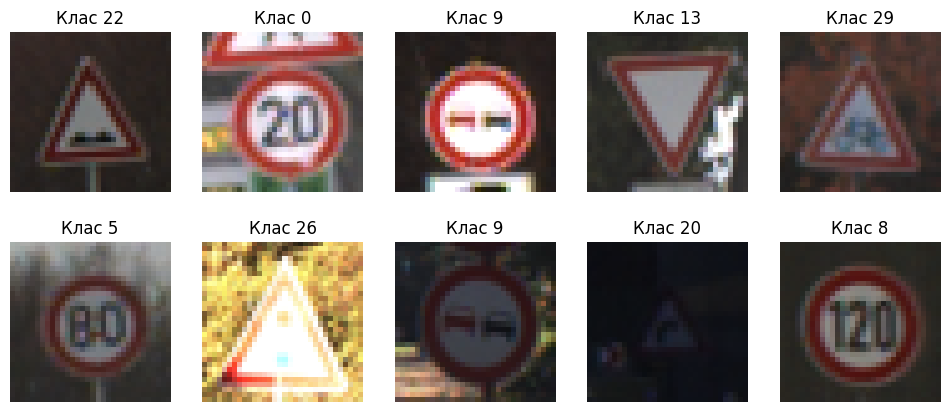

In [ ]:
#Виводжу 10 випадкових картинок з навчальної вибірки
plt.figure(figsize=(12, 5))
for i in range(10):
    idx = np.random.randint(0, len(X_all))
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_all[idx])
    plt.title(f"Клас {y_all[idx]}")
    plt.axis("off")
plt.show()

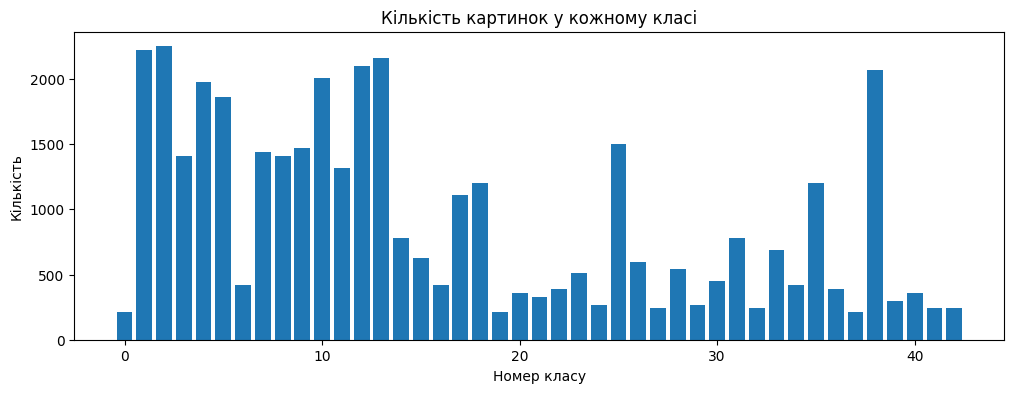

In [ ]:
#Дивлюсь, скільки картинок у кожному класі
plt.figure(figsize=(12, 4))
plt.bar(range(43), np.bincount(y_all))
plt.title("Кількість картинок у кожному класі")
plt.xlabel("Номер класу")
plt.ylabel("Кількість")
plt.show()

**Висновок з перегляду:** класи розподілені нерівномірно, деяких знаків дуже багато, а деяких зовсім мало. Картинки маленькі, різної якості та освітлення.

## 3. Підготовка даних

In [ ]:
#Нормалізую значення пікселів, щоб вони були від 0 до 1
X_all = X_all.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

#Ділю навчальні дані на навчальну (80%) та валідаційну (20%) вибірки
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (31367, 32, 32, 3)
Validation: (7842, 32, 32, 3)
Test: (12630, 32, 32, 3)


## 4. Архітектура моделі

Я спробую дві архітектури і порівняю їх:
* **Модель 1:** проста, один згортковий шар.
* **Модель 2:** глибша, чотири згорткових шари, MaxPooling та Dropout (щоб зменшити перенавчання).

In [ ]:
#Створюю модель 1 (проста)
model1 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(43, activation="softmax")
])

model1.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       460,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         2,795 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 464,555 (1.77 MB)

 Trainable params: 464,555 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Створюю модель 2 (глибша)
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(43, activation="softmax")
])

model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,699 (2.54 MB)

 Trainable params: 666,699 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Навчання та криві навчання

In [ ]:
#Пишу функцію для побудови кривих навчання
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Навчання")
    plt.plot(history.history["val_accuracy"], label="Валідація")
    plt.title(title + ": точність")
    plt.xlabel("Епоха")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Навчання")
    plt.plot(history.history["val_loss"], label="Валідація")
    plt.title(title + ": втрати")
    plt.xlabel("Епоха")
    plt.ylabel("Loss")
    plt.legend()

    plt.show()

### Навчання моделі 1

In [ ]:
#Навчаю модель 1
history1 = model1.fit(X_train, y_train, epochs=10, batch_size=64,
                      validation_data=(X_val, y_val))

Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 49ms/step - accuracy: 0.6188 - loss: 1.5195 - val_accuracy: 0.8531 - val_loss: 0.5985
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step - accuracy: 0.9059 - loss: 0.3882 - val_accuracy: 0.9306 - val_loss: 0.2880
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.9505 - loss: 0.2130 - val_accuracy: 0.9593 - val_loss: 0.1899
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.9681 - loss: 0.1394 - val_accuracy: 0.9640 - val_loss: 0.1578
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.9771 - loss: 0.1008 - val_accuracy: 0.9645 - val_loss: 0.1553
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.9830 - loss: 0.0741 - val_accuracy: 0.9700 - val_loss: 0.1261
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 42s 53ms/step - accuracy: 0.9869 - loss: 0.0583 - val_accuracy: 0.9680 - val_loss: 0.1359
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.9887 - loss: 0.0509 - 

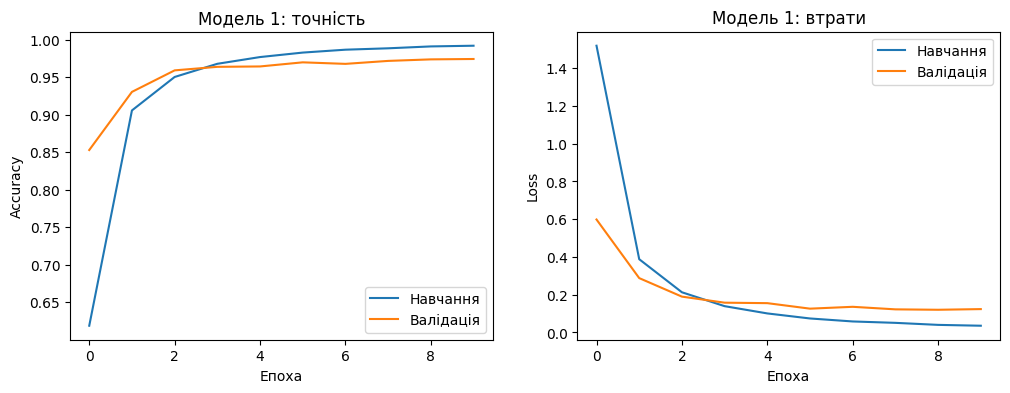

In [ ]:
#Будую криві навчання для моделі 1
plot_history(history1, "Модель 1")

### Навчання моделі 2

In [ ]:
#Навчаю модель 2
history2 = model2.fit(X_train, y_train, epochs=10, batch_size=64,
                      validation_data=(X_val, y_val))

Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 152s 304ms/step - accuracy: 0.5987 - loss: 1.4192 - val_accuracy: 0.9662 - val_loss: 0.1287
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 150s 306ms/step - accuracy: 0.9401 - loss: 0.1981 - val_accuracy: 0.9895 - val_loss: 0.0448
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 199s 300ms/step - accuracy: 0.9669 - loss: 0.1089 - val_accuracy: 0.9941 - val_loss: 0.0253
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 149s 304ms/step - accuracy: 0.9762 - loss: 0.0754 - val_accuracy: 0.9953 - val_loss: 0.0188
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 152s 310ms/step - accuracy: 0.9833 - loss: 0.0553 - val_accuracy: 0.9955 - val_loss: 0.0184
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 199s 304ms/step - accuracy: 0.9853 - loss: 0.0492 - val_accuracy: 0.9971 - val_loss: 0.0140
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 202s 304ms/step - accuracy: 0.9864 - loss: 0.0444 - val_accuracy: 0.9962 - val_loss: 0.0169
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 148s 302ms/step - accuracy: 0.9876 -

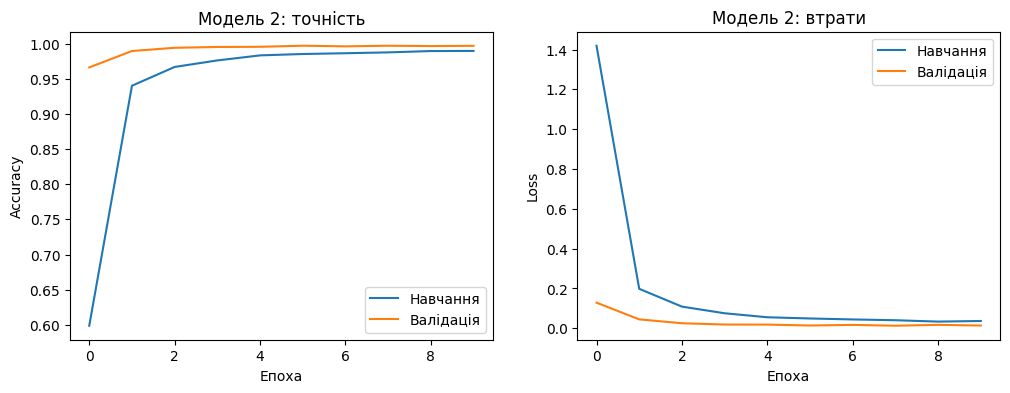

In [ ]:
#Будую криві навчання для моделі 2
plot_history(history2, "Модель 2")

## 6. Порівняння архітектур

In [ ]:
#Перевіряю обидві моделі на тестових даних
loss1, acc1 = model1.evaluate(X_test, y_test, verbose=0)
loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

results = pd.DataFrame({
    "Модель": ["Модель 1 (проста)", "Модель 2 (глибша)"],
    "Точність на тесті": [round(acc1, 4), round(acc2, 4)],
    "Втрати на тесті": [round(loss1, 4), round(loss2, 4)]
})
results

,Модель,Точність на тесті,Втрати на тесті
0,Модель 1 (проста),0.8984,0.5756
1,Модель 2 (глибша),0.9763,0.0999


In [ ]:
#Вибираю найкращу модель за точністю на тесті
if acc2 > acc1:
    best_model = model2
    print("Найкраща модель: модель 2, точність", round(acc2, 4))
else:
    best_model = model1
    print("Найкраща модель: модель 1, точність", round(acc1, 4))

Найкраща модель: модель 2, точність 0.9763


## 7. Візуалізація класифікації

In [ ]:
#Роблю прогноз для всіх тестових картинок
pred = best_model.predict(X_test)
pred_classes = np.argmax(pred, axis=1)

print("Правильно розпізнано:", np.sum(pred_classes == y_test), "з", len(y_test))

395/395 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step
Правильно розпізнано: 12331 з 12630


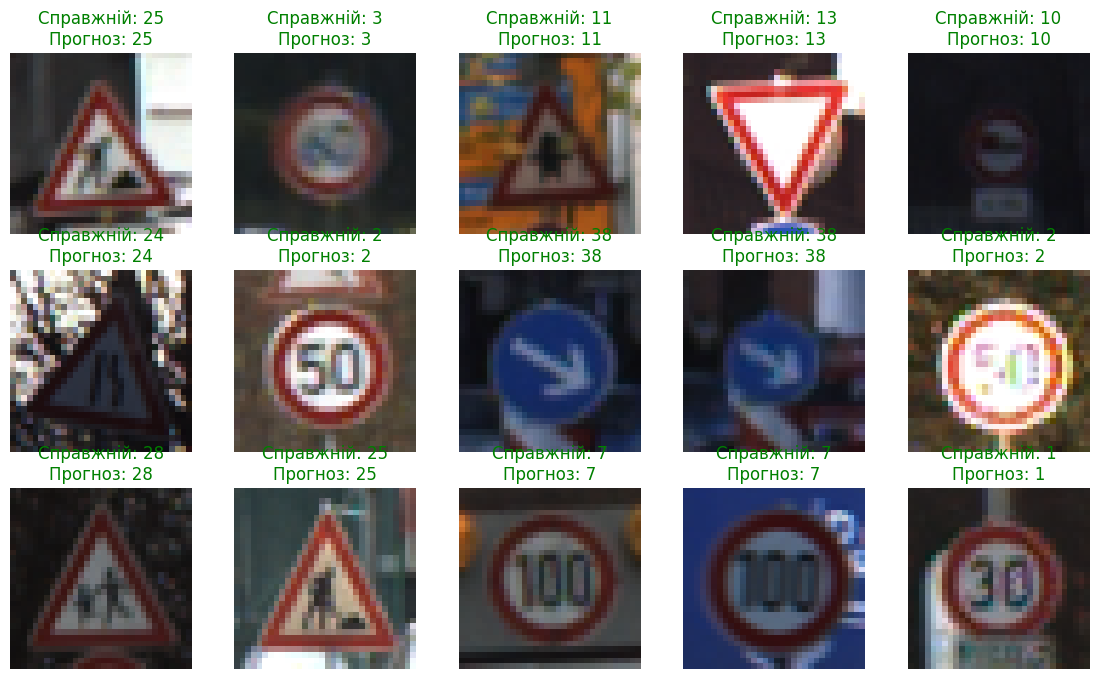

In [ ]:
#Виводжу 15 випадкових картинок: справжній і прогнозований клас
plt.figure(figsize=(14, 8))
for i in range(15):
    idx = np.random.randint(0, len(X_test))
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[idx])
    if pred_classes[idx] == y_test[idx]:
        color = "green"
    else:
        color = "red"
    plt.title(f"Справжній: {y_test[idx]}\nПрогноз: {pred_classes[idx]}", color=color)
    plt.axis("off")
plt.show()

Кількість помилок: 299


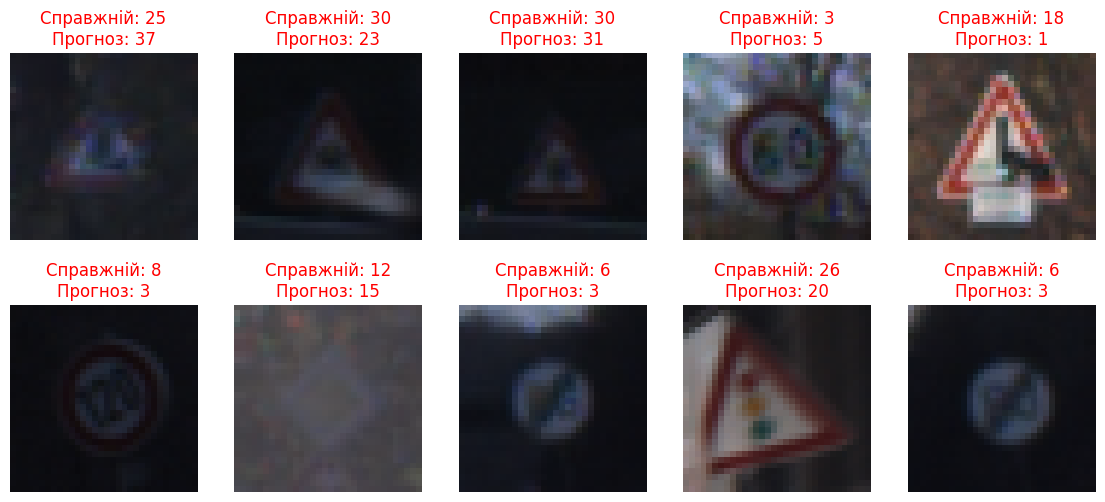

In [ ]:
#Виводжу картинки, де модель помилилась
wrong = np.where(pred_classes != y_test)[0]
print("Кількість помилок:", len(wrong))

plt.figure(figsize=(14, 6))
for i in range(10):
    idx = wrong[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f"Справжній: {y_test[idx]}\nПрогноз: {pred_classes[idx]}", color="red")
    plt.axis("off")
plt.show()

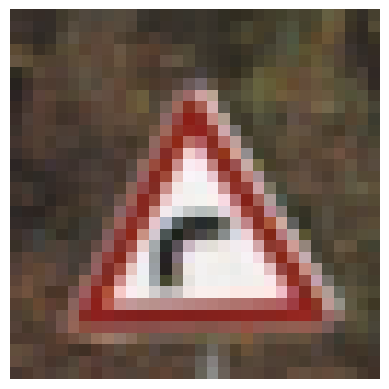

Справжній знак: Небезпечний поворот праворуч
Прогноз моделі: Небезпечний поворот праворуч


In [ ]:
#Показую одну картинку з назвами класів
idx = np.random.randint(0, len(X_test))
plt.imshow(X_test[idx])
plt.axis("off")
plt.show()

print("Справжній знак:", class_names[y_test[idx]])
print("Прогноз моделі:", class_names[pred_classes[idx]])

## 8. Висновки

1.   Я завантажила набір даних GTSRB (понад 39 тисяч навчальних і 12 тисяч тестових зображень дорожніх знаків 43 класів) і привела всі картинки до розміру 32 на 32 пікселі.
2.   Я побудувала дві згорткові нейронні мережі: просту з одним згортковим шаром і глибшу з чотирма згортковими шарами та Dropout, і порівняла їх.
3. Глибша мережа показала значно кращу точність на тестових даних (97.6% проти 89.8%), тому вона стала найкращою моделлю.
4. За кривими навчання видно, що проста мережа швидко запам'ятовує навчальні дані (точність на навчанні близько 99%) і гірше працює на нових, тобто перенавчається, а Dropout у глибшій мережі допомагає цьому запобігти.
5. Найкраща модель правильно розпізнала 12331 з 12630 тестових картинок і помилилась на 299, тому для покращення можна додати аугментацію даних і збільшити розмір зображень
